Dataset created successfully!
                                    review  sentiment
0   The movie was excellent and I loved it          1
1       This movie was terrible and boring          0
2  The acting was fantastic and impressive          1
3         I did not like this movie at all          0
4  The story was wonderful and interesting          1
Dataset shape: (30, 2)
sentiment
1    15
0    15
Name: count, dtype: int64

Original Review:
The movie was excellent and I loved it

Sequence:
[2, 3, 4, 15, 6, 5, 16, 17]

Padded Sequence:
[ 2  3  4 15  6  5 16 17  0  0  0  0  0  0  0  0  0  0  0  0]

Training samples: 24
Testing samples: 6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 213ms/step - accuracy: 0.5789 - loss: 0.6983 - val_accuracy: 0.2000 - val_loss: 0.6862
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.7895 - loss: 0.6540 - val_accuracy: 0.4000 - val_loss: 0.7057
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.9474 - loss: 0.5951 - val_accuracy: 0.4000 - val_loss: 0.7226
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.9474 - loss: 0.5230 - val_accuracy: 0.4000 - val_loss: 0.7437
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 1.0000 - loss: 0.4248 - val_accuracy: 0.4000 - val_loss: 0.7933
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.3015 - val_accuracy: 0.4000 - val_loss: 0.8942
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.1984 - val_accuracy: 0.4000 - val_loss: 1.0007
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.1163 - val_accuracy: 0.4000 - val_loss: 1.0969

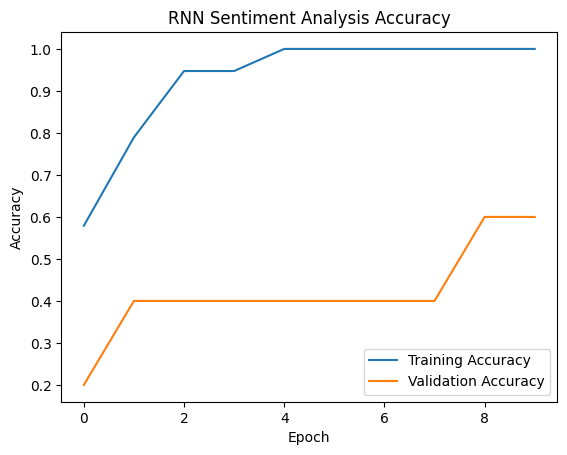


Result: Simple RNN sentiment analysis completed.


In [1]:
# Experiment No. 7
# RNN for Sentiment Analysis
# 1 = Positive, 0 = Negative

# 1. Import required libraries
import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# 2. Create the sentiment dataset automatically
data = {
    "review": [
        "The movie was excellent and I loved it",
        "This movie was terrible and boring",
        "The acting was fantastic and impressive",
        "I did not like this movie at all",
        "The story was wonderful and interesting",
        "The film was a complete waste of time",
        "I really enjoyed watching this movie",
        "The movie was disappointing and poorly made",
        "The actors did an amazing job",
        "The story was dull and predictable",
        "This is one of the best movies I have seen",
        "I regret watching this terrible film",
        "The direction and acting were excellent",
        "The movie was too slow and boring",
        "I absolutely loved the story",
        "The characters were annoying and uninteresting",
        "It was an entertaining and enjoyable movie",
        "The film failed to keep me interested",
        "I would definitely recommend this movie",
        "I would never recommend this movie",
        "The movie had a beautiful story",
        "The acting was very poor",
        "I had a great time watching this film",
        "This was the worst movie I have watched",
        "The performances were outstanding",
        "The plot made no sense",
        "The movie was surprisingly good",
        "I was completely disappointed by the movie",
        "The story kept me interested until the end",
        "The movie was not worth my time"
    ],
    "sentiment": [
        1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
        1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
        1, 0, 1, 0, 1, 0, 1, 0, 1, 0
    ]
}

df = pd.DataFrame(data)

# Save dataset as CSV
df.to_csv("sentiment_dataset.csv", index=False)

print("Dataset created successfully!")
print(df.head())
print("Dataset shape:", df.shape)
print(df["sentiment"].value_counts())

# 3. Separate input and output
X = df["review"]
y = df["sentiment"]

# 4. Convert text into numerical sequences
vocab_size = 5000
max_length = 20

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X)

sequences = tokenizer.texts_to_sequences(X)

print("\nOriginal Review:")
print(X.iloc[0])

print("\nSequence:")
print(sequences[0])

# 5. Apply padding
X_pad = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post"
)

print("\nPadded Sequence:")
print(X_pad[0])

# 6. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_pad,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 7. Design the Simple RNN model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=32
    ),
    SimpleRNN(32),
    Dense(1, activation="sigmoid")
])

# 8. Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

# 9. Train the RNN
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

# 10. Evaluate the model
loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy)

# 11. Confusion matrix and classification report
y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

# 12. Function to predict sentiment of a new review
def predict_sentiment(review):
    seq = tokenizer.texts_to_sequences([review])

    padded = pad_sequences(
        seq,
        maxlen=max_length,
        padding="post"
    )

    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Sentiment: Positive")
    else:
        print("Sentiment: Negative")

    print("Prediction Score:", float(prediction))

# 13. Test with new reviews
print("\nPositive Review Test:")
predict_sentiment(
    "The movie was amazing and I really enjoyed it"
)

print("\nNegative Review Test:")
predict_sentiment(
    "The movie was boring and I hated it"
)

# 14. Plot training and validation accuracy
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("RNN Sentiment Analysis Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 15. Result
print("\nResult: Simple RNN sentiment analysis completed.")